Cleaning the datase

In [1]:
import pandas as pd
df=pd.read_csv('station_day.csv')


In [2]:
df.head()

,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate


In [3]:
df.shape

(108035, 16)

In [4]:
df.isnull().sum()

StationId         0
Date              0
PM2.5         21625
PM10          42706
NO            17106
NO2           16547
NOx           15500
NH3           48105
CO            12998
SO2           25204
O3            25568
Benzene       31455
Toluene       38702
Xylene        85137
AQI           21010
AQI_Bucket    21010
dtype: int64

In [5]:
#remove all the rows with null values in AQI and AQI_Bucket columns
df.dropna(subset=['AQI','AQI_Bucket'],inplace=True)

In [6]:
df.isnull().sum()


StationId         0
Date              0
PM2.5          3488
PM10          23961
NO             2229
NO2            1566
NOx            4555
NH3           29832
CO             2896
SO2            9533
O3             9598
Benzene       19787
Toluene       26324
Xylene        67584
AQI               0
AQI_Bucket        0
dtype: int64

In [7]:
#dropping the columns which are not required for the analysis
df=df.drop(['Date'],axis=1)

In [8]:
df.columns

Index(['StationId', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')

In [9]:
df.isnull().sum()

StationId         0
PM2.5          3488
PM10          23961
NO             2229
NO2            1566
NOx            4555
NH3           29832
CO             2896
SO2            9533
O3             9598
Benzene       19787
Toluene       26324
Xylene        67584
AQI               0
AQI_Bucket        0
dtype: int64

In [10]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

print(missing_percent.sort_values(ascending=False))

Xylene        77.660442
NH3           34.279805
Toluene       30.248779
PM10          27.533467
Benzene       22.737144
O3            11.029015
SO2           10.954323
NOx            5.234128
PM2.5          4.008044
CO             3.327779
NO             2.561333
NO2            1.799483
StationId      0.000000
AQI            0.000000
AQI_Bucket     0.000000
dtype: float64


In [11]:
df.drop(['Xylene'],axis=1,inplace=True)

In [12]:
df.columns

Index(['StationId', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket'],
      dtype='object')

In [89]:
#performing univarate analysis on the columns to check the distribution of the data and to check for outliers
data={
    'NH3','Toluene','PM10','Benzene'      
}
df2=pd.DataFrame(data)


In [13]:
#first knowing the type of the columns in the dataset
df.dtypes

StationId      object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
AQI           float64
AQI_Bucket     object
dtype: object

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

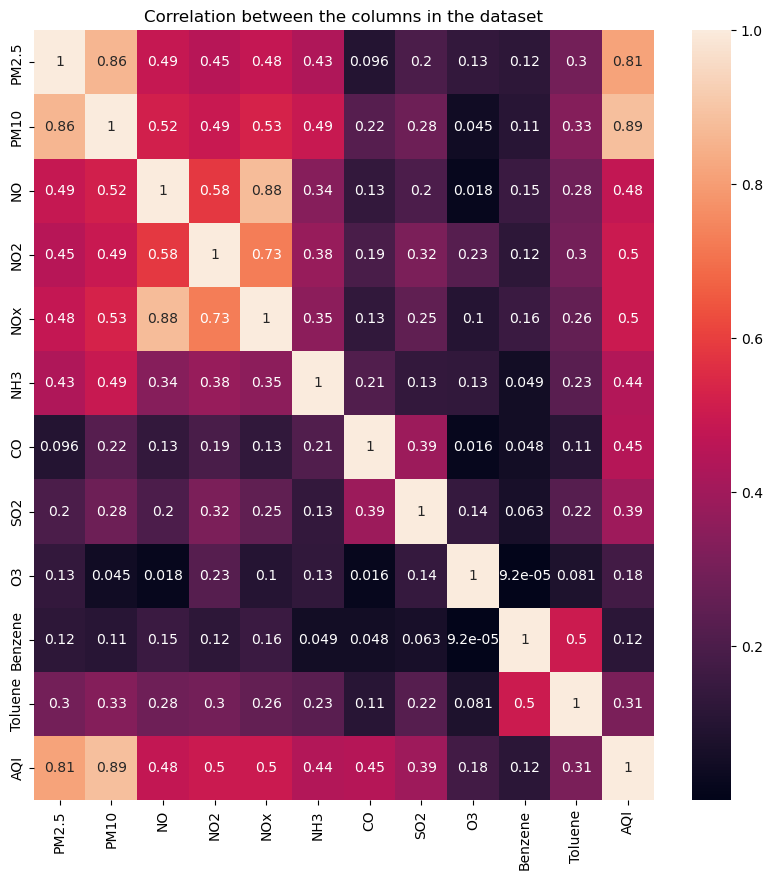

In [14]:
#correlation between the columns in the dataset
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True)
plt.title('Correlation between the columns in the dataset')
plt.show()


Checking for ouliers in NH3

In [15]:
df.isnull().sum()

StationId         0
PM2.5          3488
PM10          23961
NO             2229
NO2            1566
NOx            4555
NH3           29832
CO             2896
SO2            9533
O3             9598
Benzene       19787
Toluene       26324
AQI               0
AQI_Bucket        0
dtype: int64

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

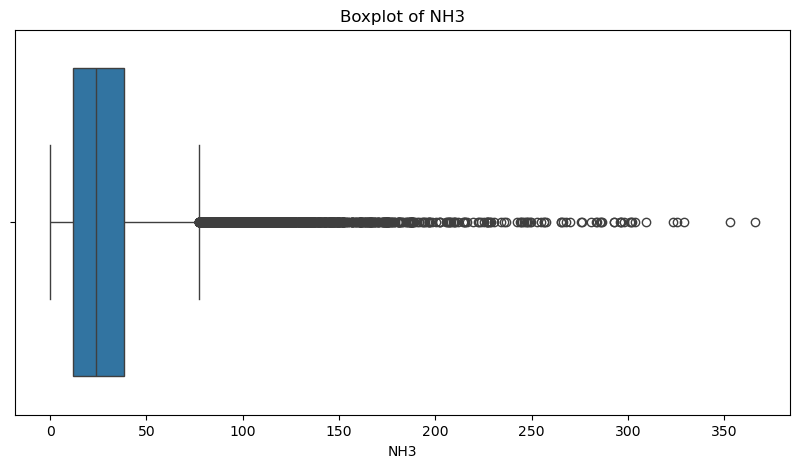

In [16]:
#In order to check outliers for NH3 performing boxplot for NH3 column in the dataset
plt.figure(figsize=(10,5))
sns.boxplot(x=df['NH3'],vert=False)
plt.title('Boxplot of NH3')
plt.show()

In [17]:
df['PM2.5']=df.groupby('StationId')['PM2.5'].transform(lambda x: x.fillna(x.median()))

In [18]:
df.isnull().sum()

StationId         0
PM2.5          2250
PM10          23961
NO             2229
NO2            1566
NOx            4555
NH3           29832
CO             2896
SO2            9533
O3             9598
Benzene       19787
Toluene       26324
AQI               0
AQI_Bucket        0
dtype: int64

Filling null values of NH3 with Median a

In [94]:
df['NH3'].describe()

count    57193.000000
mean        28.654163
std         24.014449
min          0.010000
25%         12.050000
50%         23.760000
75%         38.150000
max        365.680000
Name: NH3, dtype: float64

Using groupby to fill null values using median for that specific id

In [95]:
df.dtypes

StationId      object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
AQI           float64
AQI_Bucket     object
dtype: object

In [ ]:
numeric_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx',
                'NH3', 'CO', 'SO2', 'O3',
                'Benzene', 'Toluene']

for col in numeric_cols:
    df['PM2.5']=df.groupby('StationId')['PM2.5'].transform(lambda x: x.fillna(x.median()))

In [97]:
df.isnull().sum()

StationId         0
PM2.5          2250
PM10          21750
NO              663
NO2               0
NOx            1434
NH3           28209
CO                0
SO2            7528
O3             7680
Benzene       13494
Toluene       19029
AQI               0
AQI_Bucket        0
dtype: int64

In [21]:
print(df['NH3'].isnull().sum())

0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

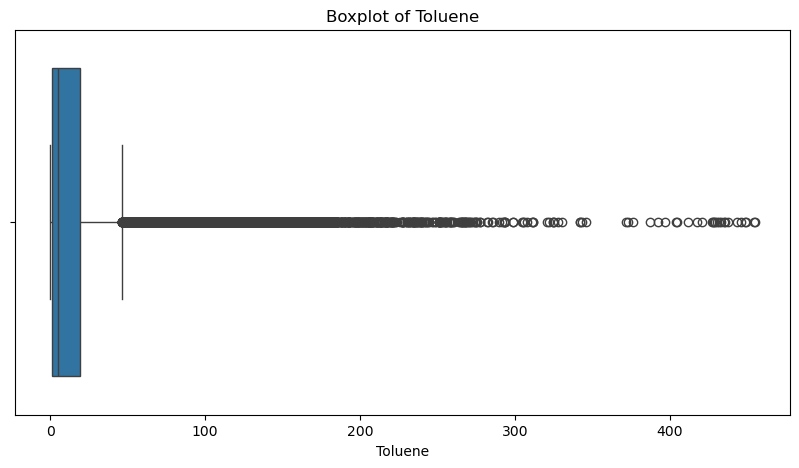

In [22]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['Toluene'])
plt.title('Boxplot of Toluene')
plt.show()


In [23]:
df['Toluene'].fillna(df['Toluene'].median(),inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\3268655383.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Toluene'].fillna(df['Toluene'].median(),inplace=True)


In [24]:
df['Toluene'].isnull().sum()

np.int64(0)

In [25]:
df.isnull().sum()

StationId         0
PM2.5          3488
PM10          23961
NO             2229
NO2            1566
NOx            4555
NH3               0
CO             2896
SO2            9533
O3             9598
Benzene       19787
Toluene           0
AQI               0
AQI_Bucket        0
dtype: int64

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\4189029469.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['PM10'],bins=30)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

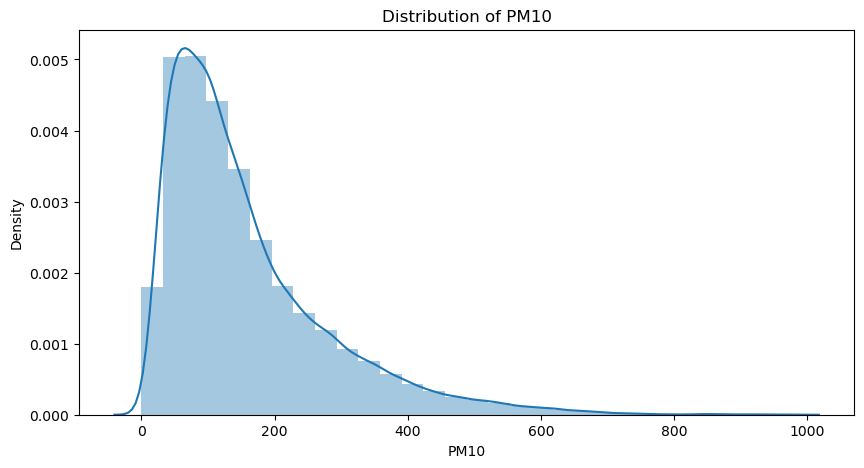

In [26]:
#plotting PM10 column to see the distribution of the data and to check for outliers
plt.figure(figsize=(10,5))
sns.distplot(df['PM10'],bins=30)
plt.title('Distribution of PM10')
plt.show()


In [27]:
df['PM10'].fillna(df['PM10'].median(),inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\1639907729.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['PM10'].fillna(df['PM10'].median(),inplace=True)


In [28]:
df['PM10'].isnull().sum()

np.int64(0)

Benzene Distribution

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 1000x500 with 0 Axes>

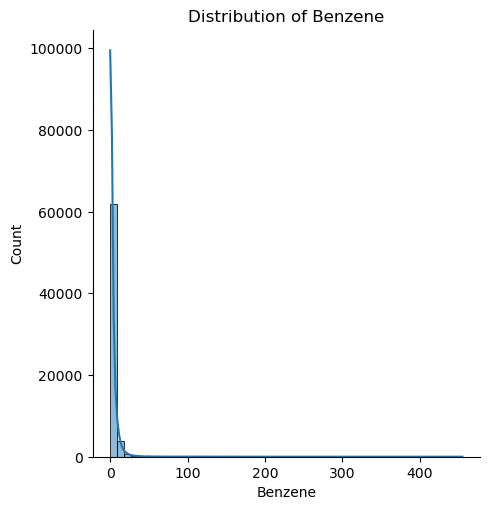

In [29]:
plt.figure(figsize=(10,5))
sns.displot(df['Benzene'],bins=50,kde=True)
plt.title('Distribution of Benzene')
plt.show()  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

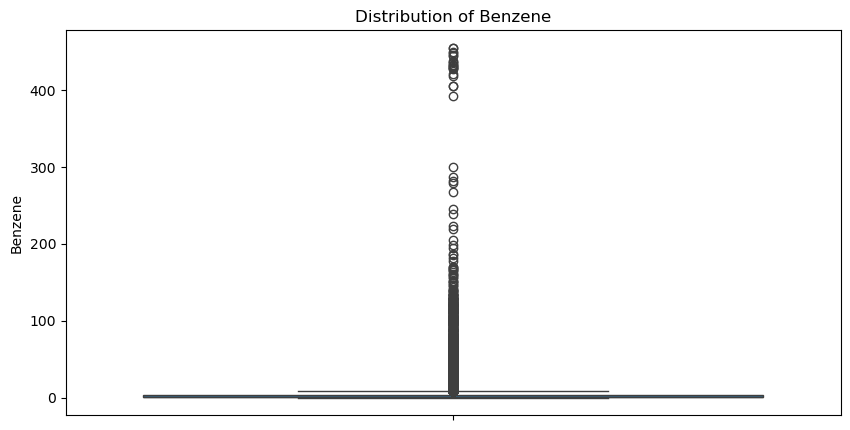

In [30]:
plt.figure(figsize=(10,5))
sns.boxplot(df['Benzene'])
plt.title('Distribution of Benzene')
plt.show()  

In [31]:
df['Benzene'].fillna(df['Benzene'].median(),inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\1261290487.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Benzene'].fillna(df['Benzene'].median(),inplace=True)


In [32]:
missing_values =df.isnull().sum()
percent_missing = (missing_values/len(df))*100
print(percent_missing.sort_values(ascending=False))

O3            11.029015
SO2           10.954323
NOx            5.234128
PM2.5          4.008044
CO             3.327779
NO             2.561333
NO2            1.799483
StationId      0.000000
PM10           0.000000
NH3            0.000000
Benzene        0.000000
Toluene        0.000000
AQI            0.000000
AQI_Bucket     0.000000
dtype: float64


Handling missing values for O3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\4139110969.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['O3'],bins=30,kde=True)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

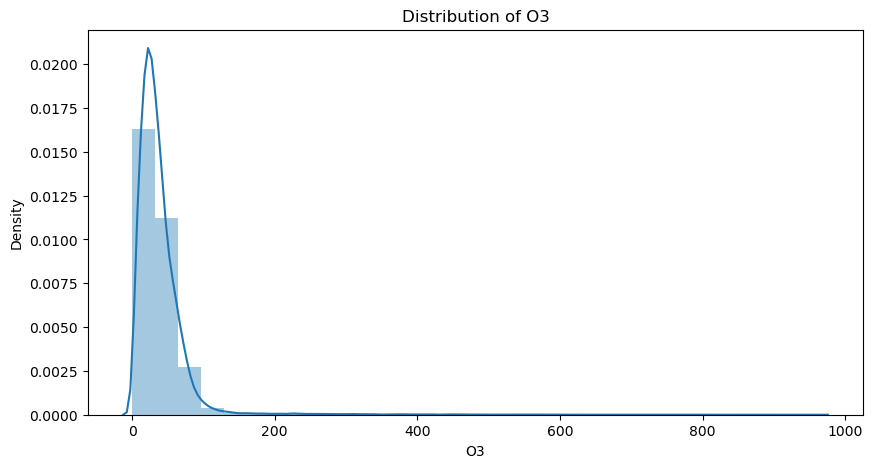

In [33]:
plt.figure(figsize=(10,5))
sns.distplot(df['O3'],bins=30,kde=True)
plt.title('Distribution of O3')
plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

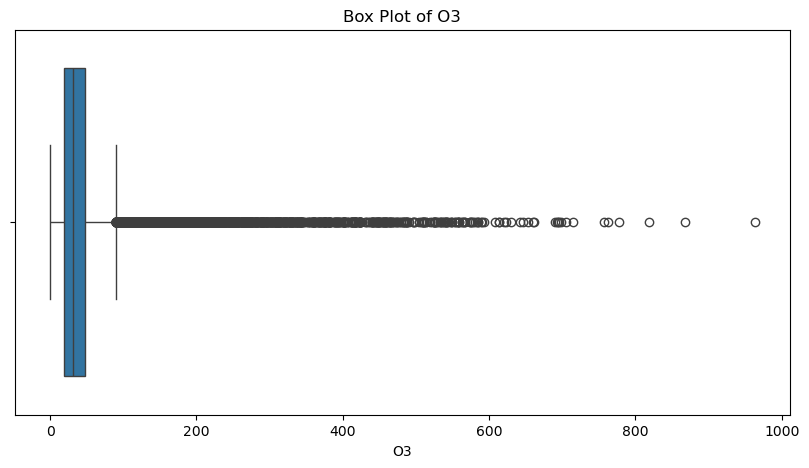

In [34]:
#box plot for O3 column to check for outliers
plt.figure(figsize=(10,5))
sns.boxplot(x=df['O3'])
plt.title('Box Plot of O3')
plt.show()

In [35]:
df['O3'].fillna(df['O3'].median(),inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\1172666675.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['O3'].fillna(df['O3'].median(),inplace=True)


Plotting for SO2

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

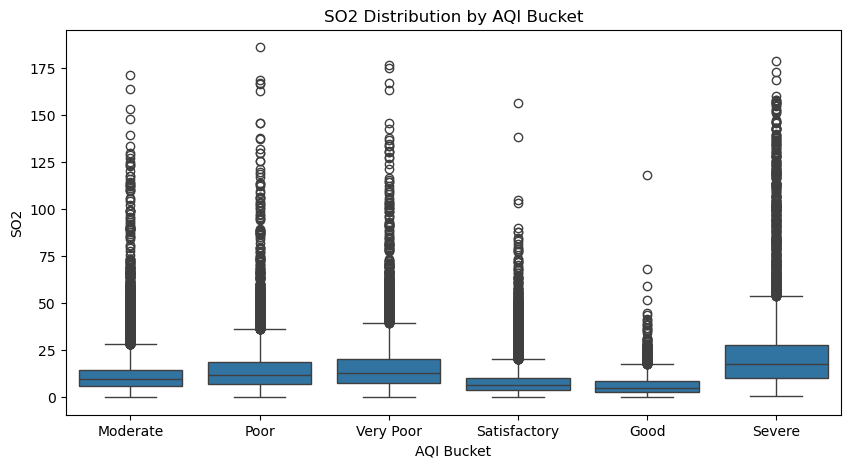

In [36]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='AQI_Bucket',
    y='SO2',
    data=df
)

plt.title('SO2 Distribution by AQI Bucket')
plt.xlabel('AQI Bucket')
plt.ylabel('SO2')

plt.show()

In [37]:
df.isnull().sum()

StationId        0
PM2.5         3488
PM10             0
NO            2229
NO2           1566
NOx           4555
NH3              0
CO            2896
SO2           9533
O3               0
Benzene          0
Toluene          0
AQI              0
AQI_Bucket       0
dtype: int64

<IPython.core.display.Javascript object>

<Axes: ylabel='SO2'>

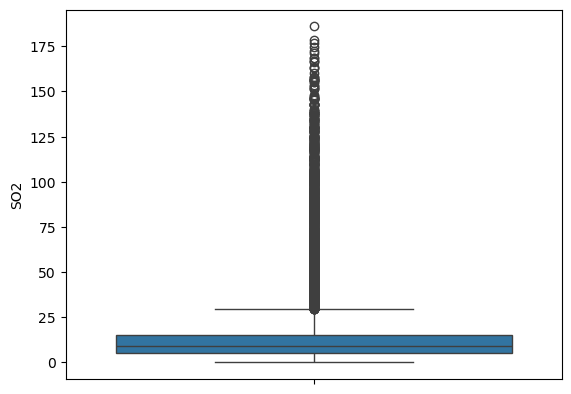

In [38]:
sns.boxplot(df['SO2'])

In [39]:
df['SO2'].describe()

count    77492.000000
mean        12.212651
std         12.464919
min          0.010000
25%          5.090000
50%          9.060000
75%         14.980000
max        186.080000
Name: SO2, dtype: float64

In [41]:
#finding mean median mode of distribution of SO2 column in the dataset
print("Mean:", df['SO2'].mean())
print("Median:", df['SO2'].median())
print("Mode:", df['SO2'].mode().iloc[0])

Mean: 12.212651241418468
Median: 9.06
Mode: 3.4


<IPython.core.display.Javascript object>

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\487863601.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['SO2'],bins=30,kde=True)


<Axes: xlabel='SO2', ylabel='Density'>

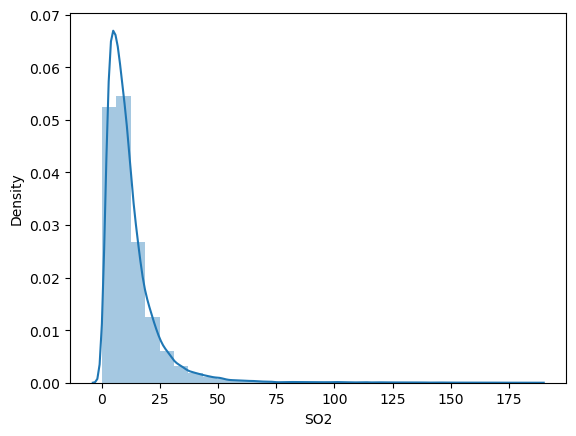

In [40]:
sns.distplot(df['SO2'],bins=30,kde=True)

In [44]:
#filling null values of SO2 column with median of the column
df['SO2'].fillna(df['SO2'].median(),inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\1481537205.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['SO2'].fillna(df['SO2'].median(),inplace=True)


In [45]:
df.isnull().sum()

StationId        0
PM2.5         3488
PM10             0
NO            2229
NO2           1566
NOx           4555
NH3              0
CO            2896
SO2              0
O3               0
Benzene          0
Toluene          0
AQI              0
AQI_Bucket       0
dtype: int64

<IPython.core.display.Javascript object>

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\926709500.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['NOx'],bins=30,kde=True)


<Axes: xlabel='NOx', ylabel='Density'>

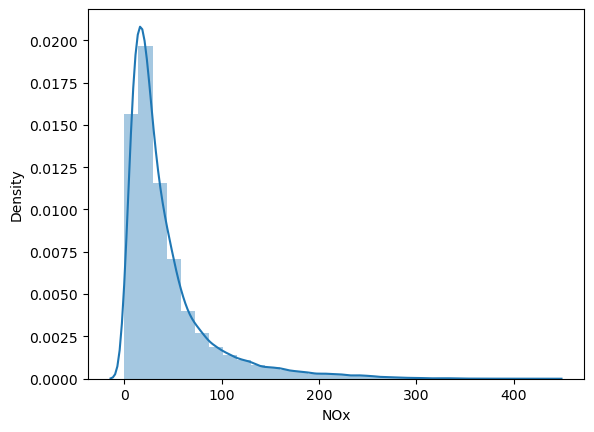

In [46]:
sns.distplot(df['NOx'],bins=30,kde=True)

In [50]:
df['NOx'].median()

28.18

In [51]:
df['NOx'].fillna(df['NOx'].median(),inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23056\2627625206.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['NOx'].fillna(df['NOx'].median(),inplace=True)


In [52]:
df.isnull().sum()

StationId        0
PM2.5         3488
PM10             0
NO            2229
NO2           1566
NOx              0
NH3              0
CO            2896
SO2              0
O3               0
Benzene          0
Toluene          0
AQI              0
AQI_Bucket       0
dtype: int64

In [55]:
df['StationId']

1         AP001
2         AP001
3         AP001
4         AP001
5         AP001
          ...  
108030    WB013
108031    WB013
108032    WB013
108033    WB013
108034    WB013
Name: StationId, Length: 87025, dtype: object